In [2]:
import numpy as np
import scipy
import pandas as pd
import matplotlib
#matplotlib.use("TkAgg")
import matplotlib.pyplot as plt
import pickle


#########################################
# Testing analytic LD in regular lattices
# - random fixed dipoles
# - should return effective kappa of 0.476
##########################################
tau = 1
rf = 1
r0=1
nrounds = 2000#00

with open(f"3D/out_kmc3D_{rf}_{tau}.pkl", "rb") as f:
    outs_3D = pickle.load(f)

with open(f"2D/out_kmc2D_{rf}_{tau}.pkl", "rb") as f:
    outs_2D = pickle.load(f)

with open(f"1D/out_kmc1D_{rf}_{tau}.pkl", "rb") as f:
    outs_1D = pickle.load(f)


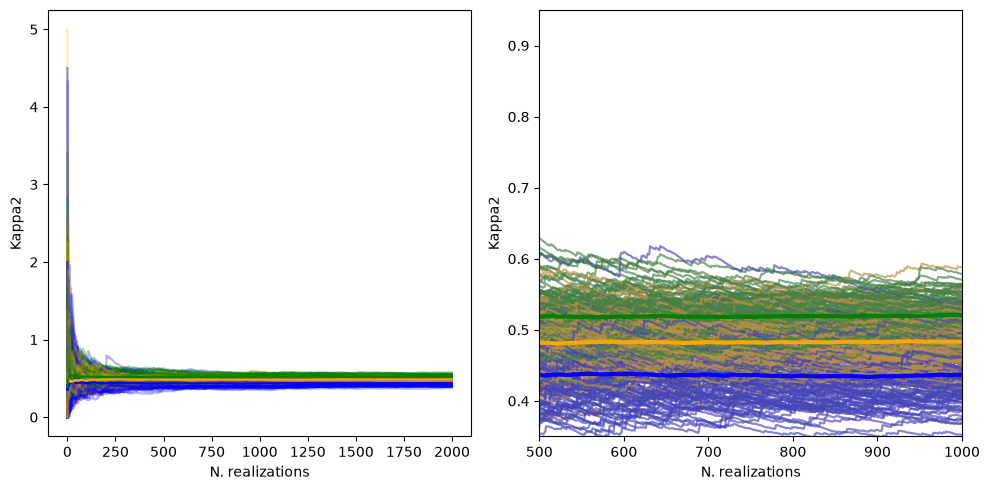

dimension = 1, kappa2=0.4396898449224612
dimension = 2, kappa2=0.4855015007503752
dimension = 3, kappa2=0.5205344338836084


In [3]:
cums_1D = np.zeros(nrounds)
cums_2D = np.zeros(nrounds)
cums_3D = np.zeros(nrounds)
images  = 100

fig,axs = plt.subplots(1,2,figsize=(10,5))
axss= axs.flatten()
alph=0.3
ax1 = axss[0]
ax2 = axss[1]
colors = ['b','orange','green']
cums   = [cums_1D,cums_2D,cums_3D]
outs   = [outs_1D,outs_2D,outs_3D]

for i in range(images):
    for j in range(3):
        out_dict = outs[j][i]
        Ds = np.array([x for x in out_dict['D']])
        Dlist = np.array([x[0] for x in out_dict['Dlist']])
        kappa2_from_out = np.array([x for x in out_dict['kappa2_list_MSD']])
        mean_from_image = np.array([ np.mean(kappa2_from_out[:n]) for n in range(1,len(kappa2_from_out)) ])
        plt.plot(np.arange(len(mean_from_image)),mean_from_image,c='grey',alpha=0.5)
        
        cum = cums[j]
        cum += kappa2_from_out
        for ax in axss:
            ax.plot(np.arange(len(mean_from_image)),mean_from_image,c=colors[j],alpha=alph)

cums_1D  = cums_1D/images
cums_2D  = cums_2D/images
cums_3D  = cums_3D/images

means_1D = np.array([ np.mean(cums_1D[:n]) for n in range(1,len(cums_1D)) ])
means_2D = np.array([ np.mean(cums_2D[:n]) for n in range(1,len(cums_2D)) ])
means_3D = np.array([ np.mean(cums_3D[:n]) for n in range(1,len(cums_3D)) ])
means = [means_1D,means_2D,means_3D]

#kappa2=(means/Ld_ana_wihtoutkappa)**2
for i,ax in enumerate(axss):
    ax.set_xlabel('N. realizations')
    ax.set_ylabel('Kappa2')
    if i ==1:
        for j in range(3):
            meansj = means[j]
            ax.plot(np.arange(len(meansj)),meansj,c=colors[j],linewidth=3)
    else:
        for j in range(3):
            meansj = means[j]
            ax.plot(np.arange(len(meansj)),meansj,c=colors[j])
ax2.set_xlim(500,1000)
ax2.set_ylim(0.35,0.95)
plt.tight_layout()
plt.show()
#print(kappa2[-1])
for i,mean in enumerate(means):
    print(f"dimension = {i+1}, kappa2={mean[-1]}")

['$\\kappa²$ 1D = 0.44', '$\\kappa²$ 2D = 0.49', '$\\kappa²$ 3D = 0.52']


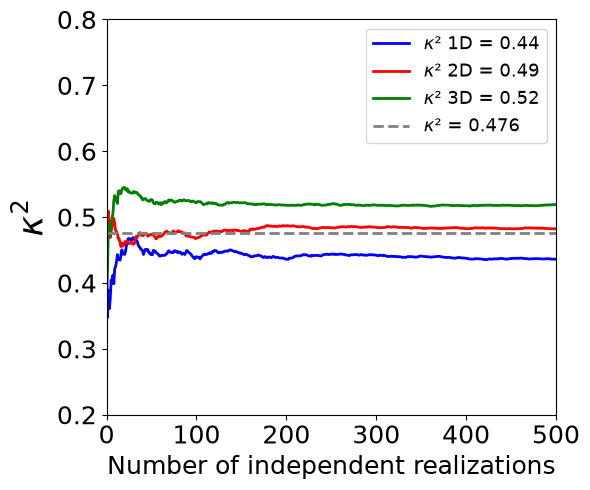

dimension = 1, kappa2=0.4396898449224612
dimension = 2, kappa2=0.4855015007503752
dimension = 3, kappa2=0.5205344338836084


In [7]:
cums_1D = np.zeros(nrounds)
cums_2D = np.zeros(nrounds)
cums_3D = np.zeros(nrounds)
images  = 100



alph=0.1

colors = ['b','r','green']
cums   = [cums_1D,cums_2D,cums_3D]
outs   = [outs_1D,outs_2D,outs_3D]

plt.figure(figsize = (6,5))
for i in range(images):
    for j in range(3):
        out_dict = outs[j][i]
        Ds = np.array([x for x in out_dict['D']])
        Dlist = np.array([x[0] for x in out_dict['Dlist']])
        kappa2_from_out = np.array([x for x in out_dict['kappa2_list_MSD']])
        mean_from_image = np.array([ np.mean(kappa2_from_out[:n]) for n in range(1,len(kappa2_from_out)) ])
        #plt.plot(np.arange(len(mean_from_image)),mean_from_image,c='grey',alpha=0.5)
        
        cum = cums[j]
        cum += kappa2_from_out
       
        #plt.plot(np.arange(len(mean_from_image)),mean_from_image,c=colors[j],alpha=alph)

cums_1D  = cums_1D/images
cums_2D  = cums_2D/images
cums_3D  = cums_3D/images

means_1D = np.array([ np.mean(cums_1D[:n]) for n in range(1,len(cums_1D)) ])
means_2D = np.array([ np.mean(cums_2D[:n]) for n in range(1,len(cums_2D)) ])
means_3D = np.array([ np.mean(cums_3D[:n]) for n in range(1,len(cums_3D)) ])
means = [means_1D,means_2D,means_3D]


plt.xlabel('Number of independent realizations', fontsize = 18)
plt.ylabel(r'$\kappa^2$',fontsize = 25)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

texto = []
for i,mean in enumerate(means):
    dim = f' {i+1}D = '
    n = f"{mean[-1]:.2f}"
    k = r'$\kappa²$'
    kk = r'{k}_{dim}'
    texto.append(k + dim +n)

print(texto)

for j in range(3):
    meansj = means[j]
    plt.plot(np.arange(len(meansj)),meansj,c=colors[j],linewidth=2, label = texto[j])

plt.xlim(0,500)
plt.ylim(0.2,0.8)
plt.tight_layout()
plt.axhline(0.476, linestyle = '--', c = 'gray', linewidth = 2, label = r'$\kappa²$ = 0.476')

plt.legend(fontsize=13)
plt.savefig('graf_rounds.png', dpi = 400)
plt.show()



for i,mean in enumerate(means):
    print(f"dimension = {i+1}, kappa2={mean[-1]}")

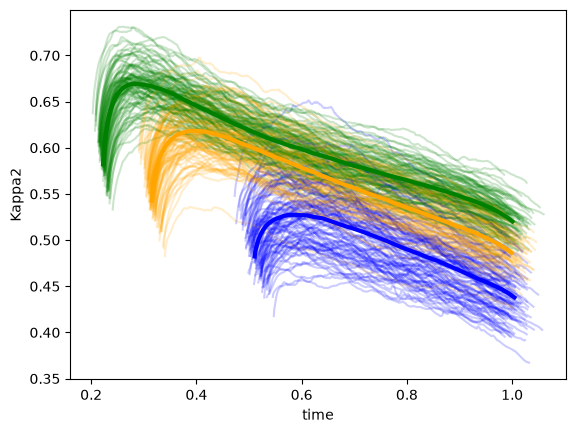

In [4]:
#plotting kappa but during time

nmeas = 500
Ttot_1D = np.zeros(nmeas)
kappas_1D=np.zeros(nmeas)
Ttot_2D = np.zeros(nmeas)
kappas_2D=np.zeros(nmeas)
Ttot_3D = np.zeros(nmeas)
kappas_3D=np.zeros(nmeas)

alph=0.2
for i in range(images):
    out_dict = outs_1D[i]
    t,k =  out_dict['Dtime']
    Ttot_1D +=t
    kappas_1D+= k
    plt.plot(t,k,c='b',alpha=alph)

    out_dict = outs_2D[i]
    t,k =  out_dict['Dtime']
    Ttot_2D +=t
    kappas_2D+= k
    plt.plot(t,k,c='orange',alpha=alph)

    out_dict = outs_3D[i]
    t,k =  out_dict['Dtime']
    Ttot_3D +=t
    kappas_3D+= k
    plt.plot(t,k,c='green',alpha=alph)
    
Ttot_1D   = Ttot_1D /images
kappas_1D  = kappas_1D /images
Ttot_2D   = Ttot_2D/images
kappas_2D = kappas_2D/images
Ttot_3D   = Ttot_3D/images
kappas_3D = kappas_3D/images
#means = np.array([ np.mean(cums[:n]) for n in range(1,len(cums)) ])
#kappa2=(means/Ld_ana_wihtoutkappa)**2

#kappa2=(means/D_nokappa)
plt.xlabel('time')
plt.ylabel('Kappa2')
plt.plot(Ttot_1D,kappas_1D,c='b',linewidth=3)
plt.plot(Ttot_2D,kappas_2D,c='orange',linewidth=3)
plt.plot(Ttot_3D,kappas_3D,c='green',linewidth=3)

plt.show()
#print(kappas[-1])